# PSA の温度ゲイン: 温度ごとの相対ゲイン(`temp_gain_haNN.csv`)

MPPC のゲインは温度で大きく変わります(UVSOR のデータで 1 °C あたり約 −8%)。
温度の違うランを合わせると、同じエネルギーの光電ピークがずれてしまうので、`PSA_Calibration` は
**`hg_corr = hg / gain(T)`** に直してからエネルギーにします。T はボードの温度センサー 6 個の平均(`temp_mean`)です。

`gain(T)` は ch ごとの表 `calib/psa/temp_gain_haNN.csv`(`ch,temp,gain`)で、行の間は直線でつなぎ、範囲の外は端の値です。
この表を較正のランから作るのが `scripts/calib/make_psa_temp_gain.py` です。

| 手順 | 中身 |
|---|---|
| 1. ヒットを選ぶ | 飽和していないもの。ピークがトリガーの時刻(`peak_id` の範囲をデータから決める。`temp_spectra.py` と同じ) |
| 2. 温度で分ける | `temp_mean` を 1 °C ごと(`--temp-width`)。ヒットが 5000(`--min-hits`)未満の区間は使わない |
| 3. 光電ピーク | 区間ごとの `hg` のスペクトルの光電ピーク(`temp_spectra.py` と同じ探し方。1.5 万より上で、十分高い山のうち一番エネルギーの高いもの) |
| 4. 相対ゲイン | `gain = ピーク(T) / ピーク(T_ref)`。T_ref は `--t-ref`、無ければヒットの一番多い区間 |

入力は、**同じ線源(同じ線)で、直したいデータの温度の範囲をカバーするもの**にします。ここでは Cs-137 の run01〜11 です。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
CALIB_SCRIPTS = REPO / "scripts" / "calib"
sys.path.insert(0, str(CALIB_SCRIPTS))
CACHE = REPO / "tutorials" / "cache"      # チェーンの出力の置き場(git には入れない)
CACHE.mkdir(exist_ok=True)
CAL_OUT = CACHE / "calib_psa"              # このノートブックで作る較正ファイル(calib/psa は上書きしない)
CAL_OUT.mkdir(exist_ok=True)
PYTHON = "/usr/bin/python3"                # scripts/calib を動かす Python(numpy, scipy, PyROOT)
DATA = Path(os.environ.get("SMILE3_PSA_CAL_DATA", "/mnt/d/UVSOR2026_late"))

def run(cmd, show=True):
    """コマンドを実行し、出力を表示する"""
    print(" ".join(str(c) for c in cmd))
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if show:
        print(r.stdout[-4000:])
    if r.returncode != 0:
        print(r.stderr[-4000:])
    r.check_returncode()

def chain(run_name, out, *args):
    """UVSOR のラン 1 本を smile3_psa で流す(出力が既にあれば何もしない)"""
    if out.exists():
        return out
    run([sys.executable, RUN_CHAIN, "smile3_psa", "-o", out, "--data-dir", DATA / "killua" / run_name,
         "--set", "PSA_ReadData.extra_data_dirs=" + json.dumps([str(DATA / "calltt" / run_name)]), *args], show=False)
    return out

## 1. データ

2026-11-03 の UVSOR での HA_cal のランを使います(解析用の計算機の D ドライブ `/mnt/d/UVSOR2026_late`。
ほかの場所にあるときは環境変数 `SMILE3_PSA_CAL_DATA`)。ランの記録は Notion の
「SMILE-3 FM UVSOR 試験(2026-11-03)データ確認と HA_cal の解析」にあります。

| ラン | 線源 | 温度 | 中身 |
|---|---|---|---|
| run01〜11 | Cs-137 | 39〜49 °C | 1 ランは約 2 分。多くは storage の OOM で途中で止まった(.dat.tmp が残る) |
| run12 | Co | 47〜49 °C | 4 時間。ha02 で 1 ch あたり 130〜160 万ヒット。ほぼ全部がトリガーの時刻に入る。ha04 は無い |

チェーンの出力は 1 ランに 1 つ、`tutorials/cache/psa_<ラン>.root` に置き、既にあれば流し直しません
(Cs は 1 ランに 1〜4 分、run12 は約 2 時間)。

In [2]:
RUNS = [f"20261103_run{k:02d}" for k in range(1, 12)]
ROOTS = [chain(r, CACHE / f"psa_{r}.root") for r in RUNS]
print(len(ROOTS), "files,", f"{sum(p.stat().st_size for p in ROOTS) / 1e9:.1f} GB")

11 files, 5.4 GB


## 2. 温度の範囲

入力のランの温度の範囲をボードごとに見ます。表はこの範囲でしか作れません(外は端の値)。

In [3]:
from psa_calib_common import read_tree
d = read_tree([str(r) for r in ROOTS], ["board", "temp_mean"], "ch == 0")
for b in np.unique(d["board"]):
    t = d["temp_mean"][d["board"] == b]
    print(f"ha{b:02d}: temp_mean {t.min():.1f} - {t.max():.1f} degC (median {np.median(t):.1f}, {len(t)} hits in ch0)")

ha00: temp_mean 39.3 - 47.9 degC (median 47.6, 454307 hits in ch0)
ha01: temp_mean 40.0 - 49.4 degC (median 47.2, 748681 hits in ch0)
ha02: temp_mean 39.5 - 47.9 degC (median 45.7, 683789 hits in ch0)
ha03: temp_mean 39.2 - 47.6 degC (median 45.5, 752107 hits in ch0)
ha04: temp_mean 40.1 - 40.6 degC (median 40.3, 1203 hits in ch0)
ha05: temp_mean 39.1 - 47.5 degC (median 45.3, 743289 hits in ch0)
ha06: temp_mean 40.8 - 46.3 degC (median 45.0, 343417 hits in ch0)
ha07: temp_mean 41.8 - 47.1 degC (median 45.9, 336652 hits in ch0)
ha09: temp_mean 42.0 - 47.0 degC (median 46.1, 445180 hits in ch0)
ha10: temp_mean 42.6 - 48.0 degC (median 46.1, 328562 hits in ch0)
ha12: temp_mean 42.4 - 47.5 degC (median 46.1, 373335 hits in ch0)


ha13: temp_mean 42.4 - 47.5 degC (median 46.2, 305657 hits in ch0)
ha15: temp_mean 41.8 - 47.0 degC (median 45.8, 285458 hits in ch0)
ha16: temp_mean 42.2 - 48.0 degC (median 46.2, 369907 hits in ch0)


## 3. 表を作る

ha02 の表を作ります(全ボードなら `--boards` を外す)。

In [4]:
run([PYTHON, CALIB_SCRIPTS / "make_psa_temp_gain.py", *ROOTS, "-o", CAL_OUT, "--boards", "2", "--overwrite"])
print("".join(l for l in open(CAL_OUT / "temp_gain_ha02.csv") if not l.startswith("# input")))

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_psa_temp_gain.py /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run01.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run02.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run03.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run04.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run05.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run06.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run07.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run08.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run09.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run10.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa

ha02: /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa/temp_gain_ha02.csv
    ch0: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.883
    ch1: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.727
    ch2: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.992
    ch3: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.913
    ch4: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-2.007
    ch5: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.836

# made by scripts/calib/make_psa_temp_gain.py, 2026-11-05T18:05:05
# hits: !satu_h && !satu_l && (board == 2), peak_id 27-29; T = temp_mean, bins of 1 degC with >= 5000 hits
# photopeak of hg above 15000 (250 bins up to 100000)
# ch0: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.883
# ch1: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.727
# ch2: 6 bins 39.5-47.5 degC, gain = 1 at 47.5 degC, gain 1.000-1.992
# ch3: 6 bins 39.5-47.5 degC, gain

## 4. 確認の図

上の段が温度の区間ごとの `hg` のスペクトル(面積で規格化)、下の段が相対ゲインです。
どの区間でも同じ山(Cs の光電ピーク、一番エネルギーの高い山)を選べていることを確かめてください。
約 2 万の段差と低い側は hit threshold・data threshold と時刻のずれた信号によるもので、温度では動きません(Notion)。

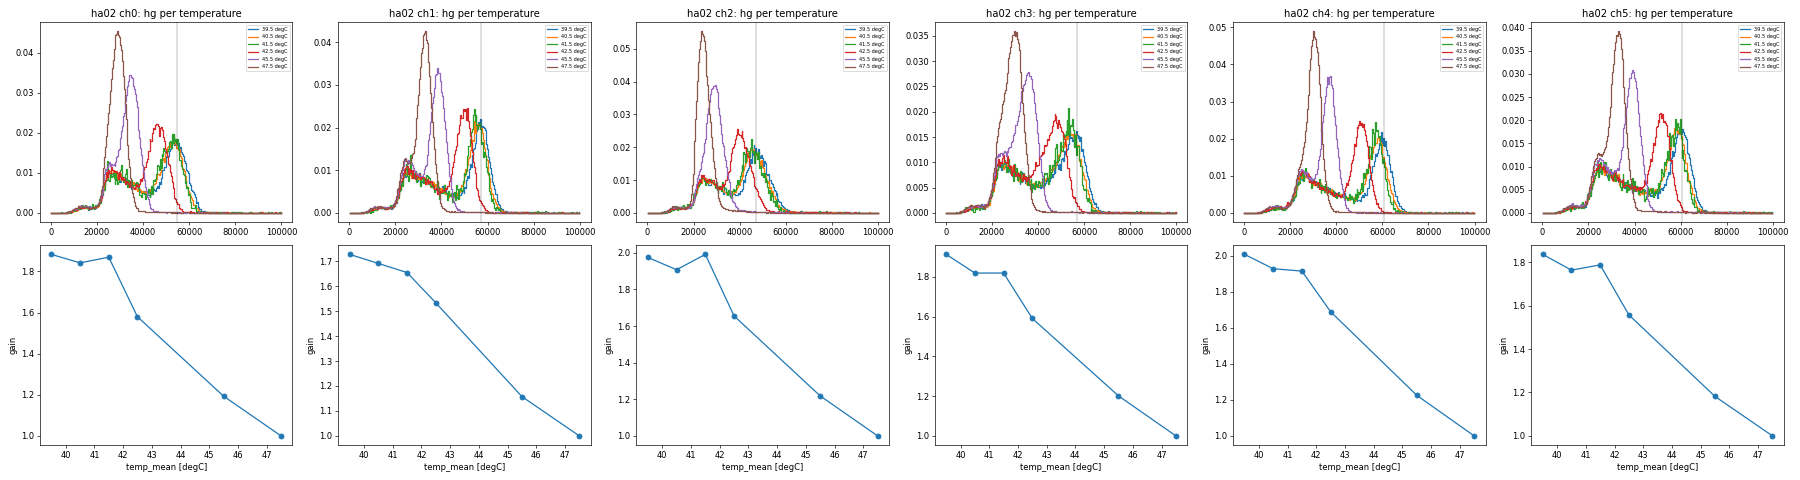

In [5]:
display(Image(filename=str(CAL_OUT / "qa" / "temp_gain_ha02.png")))

## 5. 直したスペクトル

作った表で `hg` を直し(チェーンの `PSA_Calibration` と同じ計算)、温度の区間ごとのスペクトルの光電ピークがそろうかを見ます。

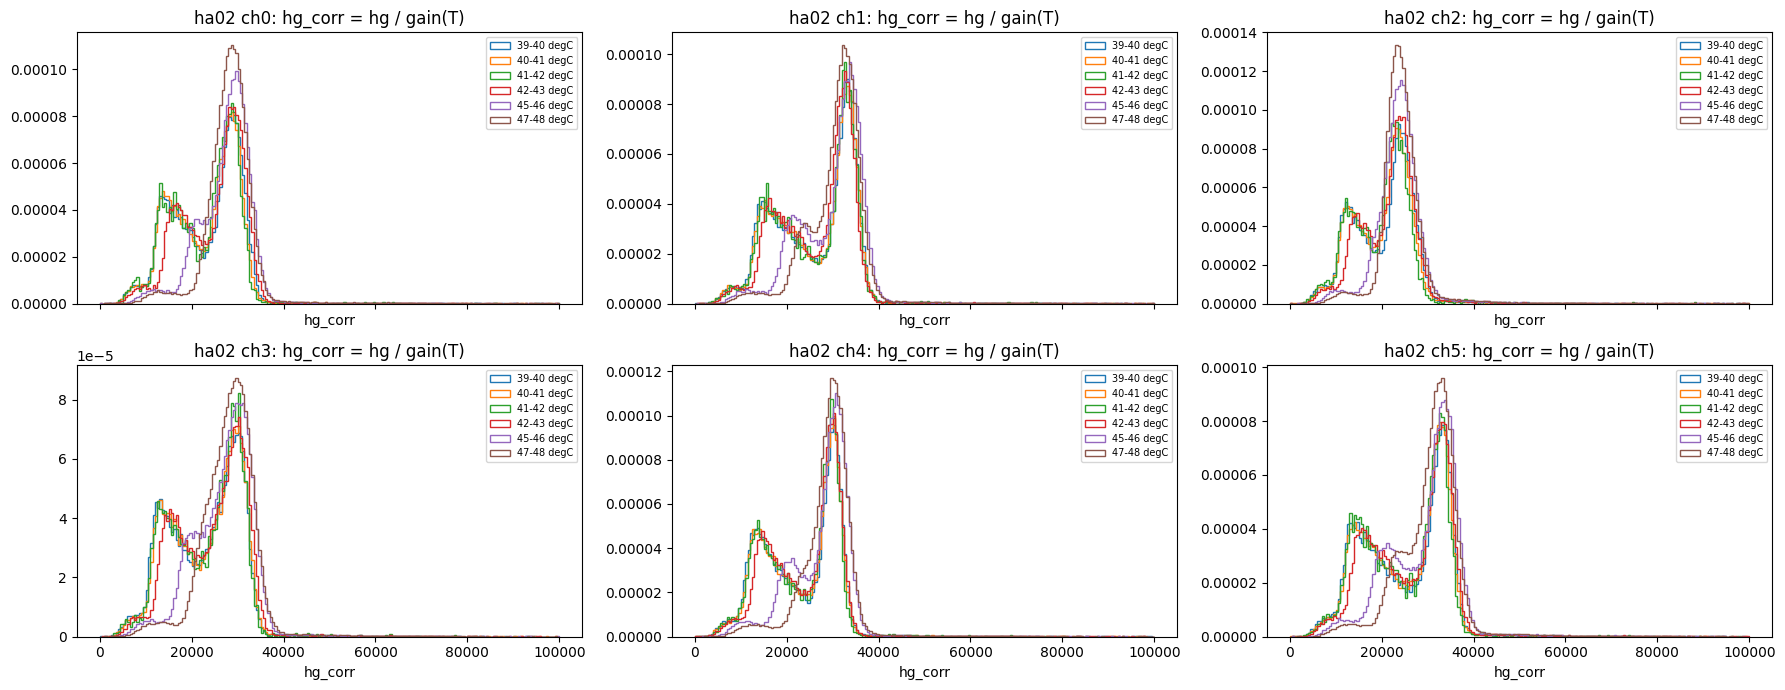

In [6]:
import csv
rows = list(csv.DictReader(l for l in open(CAL_OUT / "temp_gain_ha02.csv") if not l.startswith("#")))
table = {c: sorted((float(r["temp"]), float(r["gain"])) for r in rows if int(r["ch"]) == c) for c in range(6)}
d = read_tree([str(r) for r in ROOTS], ["ch", "hg", "temp_mean"],
              "board == 2 && !satu_h && !satu_l && peak_id >= 26 && peak_id <= 29")
fig, axs = plt.subplots(2, 3, figsize=(18, 7), sharex=True)
for c, ax in enumerate(axs.flat):
    tt, gg = np.array(table[c]).T
    s = d["ch"] == c
    corr = d["hg"][s] / np.interp(d["temp_mean"][s], tt, gg)
    for low in np.arange(np.floor(d["temp_mean"][s].min()), d["temp_mean"][s].max(), 1.0):
        m = (d["temp_mean"][s] >= low) & (d["temp_mean"][s] < low + 1)
        if m.sum() >= 5000:
            ax.hist(corr[m], bins=200, range=(0, 1e5), histtype="step", density=True, label=f"{low:.0f}-{low + 1:.0f} degC")
    ax.set_title(f"ha02 ch{c}: hg_corr = hg / gain(T)"); ax.set_xlabel("hg_corr"); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## 6. 使う

今の `calib/psa/temp_gain_haNN.csv` は、この手順で run01〜11 から全ボードを作ったものです(ha04 は Cs のランにほぼ無いので無い)。

```bash
/usr/bin/python3 scripts/calib/make_psa_temp_gain.py tutorials/cache/psa_20261103_run{01..11}.root -o calib/psa --overwrite
```